#### Slider pick-and-place with `ROBOTIS FFW SG2`
- Tabletop scene with two cans.
- Slider target drives right-arm IK.
- IK solution is applied as actuator control and executed with MuJoCo forward dynamics.


In [1]:
from package.init_scripts.init_ipython_setup import *
from package.init_scripts.init_qt import *
from package.mujoco_sim import *
from package.kinematics import *
from package.utility import *
from package.qt import *
from PyQt5.QtWidgets import QApplication
app = QApplication(sys.argv)

[qt] package initialized.
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files=[
        "../asset/floor/floor_simple_white.xml",
        "../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml",
        "../asset/object/table_0.xml",
        "../asset/objaverse/can/can_0/model_new.xml",
        "../asset/objaverse/can/can_2/model_new.xml",
        "../asset/objaverse/bowl/bowl_5/model_new.xml",
    ],
    output_xml_path = "xml/scene_ffw_sg2.xml",
)
env = MuJoCoParser(rel_xml_path=xml_path, verbose=False)


[merge_mjcfs] Merging [6] MJCF files:
  - [0] [../asset/floor/floor_simple_white.xml]
  - [1] [../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml]
  - [2] [../asset/object/table_0.xml]
  - [3] [../asset/objaverse/can/can_0/model_new.xml]
  - [4] [../asset/objaverse/can/can_2/model_new.xml]
  - [5] [../asset/objaverse/bowl/bowl_5/model_new.xml]
[merge_mjcfs] Saved merged XML to:[xml/scene_ffw_sg2.xml]
MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


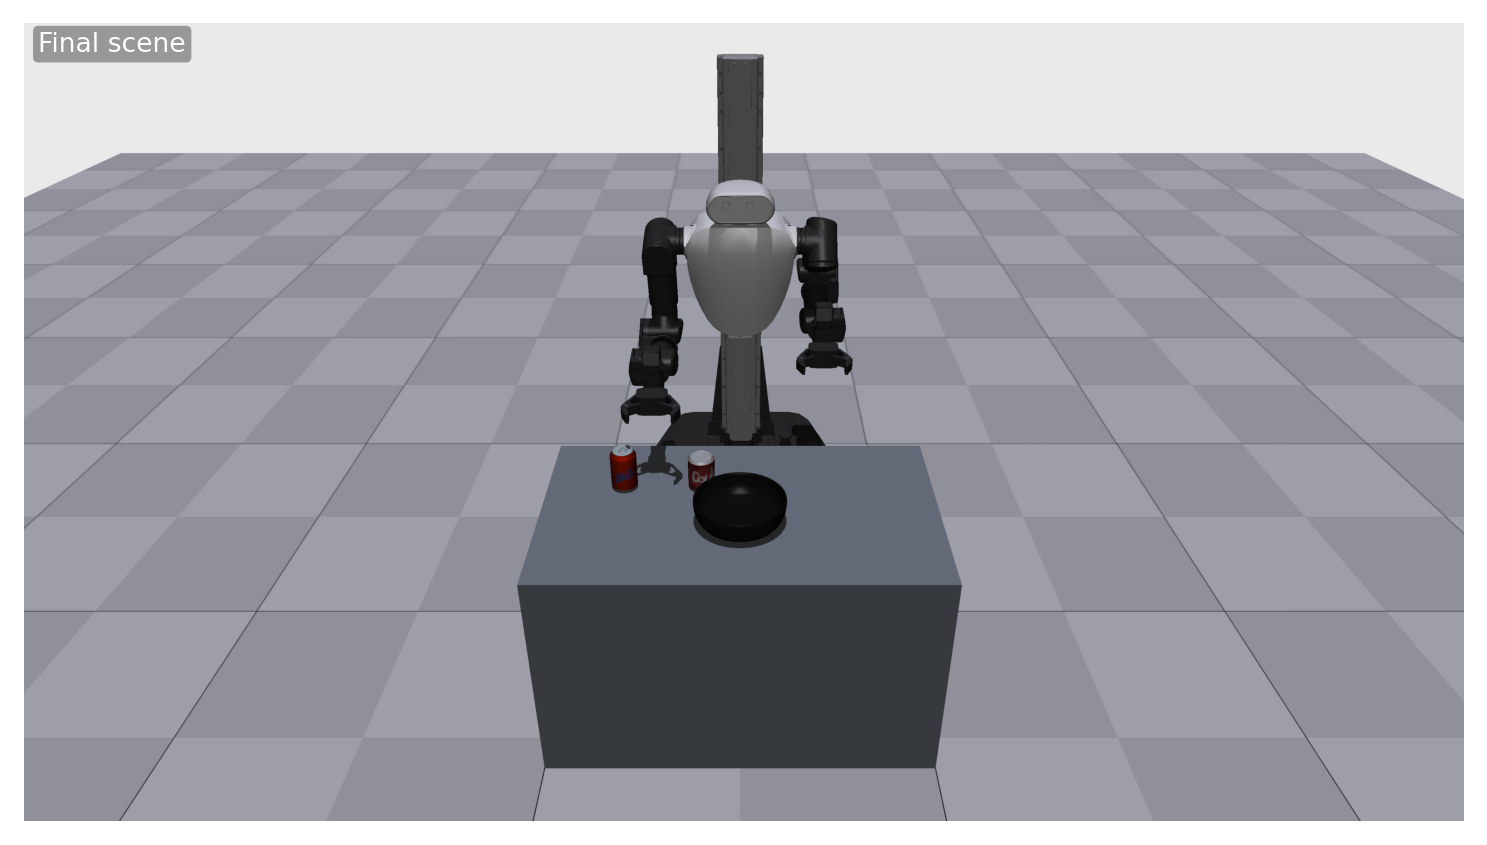

Done.


In [3]:
# Reset
env.reset()
env.init_viewer(title="FFW SG2 Slider Pick-and-Place", width=1.0, height=1.0, fontscale=200)
env.viewer.set_cam_info(180, 3.2, -30, [0.02, 0.01, 0.4])
env.viewer.set_transparency(transparent=False)
env.viewer.set_geomgroup(group_2=True, group_3=False)
env.viewer.set_sitegroup(group_0=False)

# Initial configurations
env.set_p(name="base_link", p=[0.2, 0, 0.0], type="base_body")
env.set_p("body_object_table_0", "body", (0.8, 0.0, 0.0))
env.set_p("body_obj_can_0", "base", (0.70, -0.30, 0.70))
env.set_p("body_obj_can_2", "base", (0.70, -0.10, 0.70))
env.set_p("body_obj_bowl_5", "base", (0.85, 0.00, 0.70))

def get_R_tcp(env, use_arm='r', use_type="site"):
    p_tcp        = env.get_p(f"gripper_{use_arm}_tcp",       type=use_type)
    p_tcp_top    = env.get_p(f"gripper_{use_arm}_tcp_top",   type=use_type)
    p_tcp_side   = env.get_p(f"gripper_{use_arm}_tcp_side",  type=use_type)
    p_tcp_front  = env.get_p(f"gripper_{use_arm}_tcp_front", type=use_type)
    ux = np_uv(p_tcp_front - p_tcp)
    uy = np_uv(p_tcp_side  - p_tcp)
    uz = np_uv(p_tcp_top   - p_tcp)
    return np.column_stack((ux, uy, uz)).reshape((3, 3))

# Joint groups.
joint_groups = group_by_prefix(
    items       = env.rev_pri_joint_names,
    prefix_dict = {
        "arm_l_joint_names": ["arm_l_joint"],
        "arm_r_joint_names": ["arm_r_joint"],
        "lift_joint_name":   ["lift_joint"],
        "gripper_l_joint_name": ["gripper_l_joint1"],
        "gripper_r_joint_name": ["gripper_r_joint1"],
    },
)
use_r_joint_names = joint_groups["arm_r_joint_names"]
use_l_joint_names = joint_groups["arm_l_joint_names"]
use_lift_joint_name = joint_groups["lift_joint_name"]
use_ik_joint_names = use_r_joint_names + use_l_joint_names + use_lift_joint_name
use_gripper_joint_names = joint_groups["gripper_r_joint_name"]
use_step_joint_names = use_ik_joint_names + use_gripper_joint_names

# Initial configuration
init_q_ik = [1.07, 0, 0, -2.57, 0, 0, 0] * 2 + [-0.25]
env.forward(q=init_q_ik, joint_names=use_ik_joint_names)
env.step(ctrl=[0.0], joint_names=use_gripper_joint_names, nstep=1)
env.set_zero_qvel()

# IK target sliders and control buttons
p_r_tcp = env.get_p("gripper_r_tcp", "site")
R_tcp = get_R_tcp(env, use_arm='r')
slider_vals = np.hstack([p_r_tcp, r2rpy(R_tcp)])
sliders = MultiSliderQtWidget(
    title         = "Right Arm TCP Target",
    y_offset      = 0.05,
    window_width  = 0.24,
    window_height = 0.22,
    label_texts   = ["X", "Y", "Z", "Roll", "Pitch", "Yaw"],
    slider_mins   = slider_vals - np.array([0.7, 0.7, 0.7, np.pi, np.pi, np.pi]),
    slider_maxs   = slider_vals + np.array([0.7, 0.7, 0.7, np.pi, np.pi, np.pi]),
    slider_vals   = slider_vals,
    slider_steps  = 10000,
    fontsize      = 24,
)
buttons = MultiRadioQtWidget(
    title         = "IK / Gripper",
    label_texts   = ["IK_R", "Gripper", "Gravity compensation"],
    option_texts  = [["True", "False"], ["Open", "Close"], ["On", "Off"]],
    initial_texts = ["True", "Open", "On"],
    y_offset      = 0.30,
    window_width  = 0.24,
    window_height = 0.16,
    fontsize      = 24,
)

# Instantiate IK solver.
ik_env = MuJoCoParser(rel_xml_path=env.rel_xml_path)
dls_damping = 1e-6 * np.ones(len(use_ik_joint_names))
ik_site_solver = SitePositionIKSolverRevPriBase(
    ik_env           = ik_env,
    joints_use       = use_ik_joint_names,
    max_ik_tick      = 10,
    ik_stepsize_rev  = 10 * D2R,
    ik_stepsize_pri  = 0.15,
    ik_update_th_rev = 10 * D2R,
    ik_update_th_pri = 0.15,
    dls_damping      = dls_damping,
    max_probe_rev    = 3 * D2R,
    max_probe_pri    = 0.01,
    k_null           = 0.5,
    q_home_rev_pri   = env.get_qpos(joint_names=env.rev_pri_joint_names),
)

# Loop.
sim_nstep  = 30
tmr_sim    = SimpleTimer(name="Sim", Hz=1.0 / (env.dt * sim_nstep), verbose=True)
tmr_render = SimpleTimer(name="Render", Hz=20, verbose=True)
ik_err = np.inf
qpos_used_best = env.get_qpos(joint_names=use_ik_joint_names)
ctrl_step = np.zeros(len(use_step_joint_names))
T_can0 = env.get_T("body_obj_can_0", "body")
T_can2 = env.get_T("body_obj_can_2", "body")
tmr_sim.start(); tmr_render.start(); env.reset_wall_time(); env.reset_sim_time()

while env.is_viewer_alive():
    app.processEvents()

    if tmr_sim.do_run():
        # Get target pose from sliders.
        vals = sliders.get_values()
        p_tcp_trgt = vals[:3]
        R_tcp_trgt = rpy2r(vals[3:])
        p_tcp_top_trgt   = p_tcp_trgt + 0.1 * R_tcp_trgt[:, 2]
        p_tcp_side_trgt  = p_tcp_trgt + 0.1 * R_tcp_trgt[:, 1]
        p_tcp_front_trgt = p_tcp_trgt + 0.1 * R_tcp_trgt[:, 0]

        # Solve IK to produce position-actuator targets.
        ik_site_solver.reset_buffers()
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp", p_trgt=p_tcp_trgt)
        IK_R = buttons.get_button_option("IK_R") == "True"
        weight = 1.0 if IK_R else 1e-6
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp_top",   p_trgt=p_tcp_top_trgt,   weight=weight)
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp_side",  p_trgt=p_tcp_side_trgt,  weight=weight)
        ik_site_solver.add_ik_target(site_name="gripper_r_tcp_front", p_trgt=p_tcp_front_trgt, weight=weight)
        _, ik_info = ik_site_solver.solve_ik(
            env                     = env,
            joints_use              = use_ik_joint_names,
            joint_limit_handle_flag = True,
            nullspace_control_flag  = True,
            base_control_flag       = False,
        )
        ik_err = ik_info["ik_err_best"]
        qpos_used_best = ik_info["qpos_used_best"]

        # Step forward dynamics with IK targets as controls, following 02_fd_ffw_sg2.ipynb.
        gripper_ctrl = 0.0 if buttons.get_button_option("Gripper") == "Open" else 1.0
        ctrl_step = np.concatenate([qpos_used_best, [gripper_ctrl]])
        on_flag = buttons.get_button_option("Gravity compensation") == "On"
        env.compensate_gravity(root_body_names=["base_link"], on=on_flag)
        env.step(ctrl=ctrl_step, joint_names=use_step_joint_names, nstep=sim_nstep)
        T_can0 = env.get_T("body_obj_can_0", "body")
        T_can2 = env.get_T("body_obj_can_2", "body")
        tmr_sim.end()

    if tmr_render.do_run():
        env.plot_time(plot_loop_freq=False)
        env.plot_global_coordinate_axes()
        ik_site_solver.render(env, r=0.01, scale_radius_by_weight=True)
        env.viewer_text_overlay("IK error", f"[{ik_err:.6f}]")
        env.viewer_text_overlay("Gripper", buttons.get_button_option("Gripper"))
        env.plot_contact_info(plot_contact=True, rate=0.5)
        env.plot_T(T=T_can0, axis_len=0.05)
        env.plot_T(T=T_can2, axis_len=0.05)
        env.render()
        tmr_render.end()

# Plot final scene.
imshow(env.final_rgb_img, fig_w=6, title="Final scene", title_fs=8)

# Close.
env.close_viewer()
sliders.close()
buttons.close()
print_green("Done.")

